In [2]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd 

# Feature Engineering: Price Per Square Meter 


<div class = " alert alert-block alert-success"><b>Recap</b></div>
   
**Refresh - go over simpsons paradox**

Lesson 1 - Data Structures and Descriptive Stats
Lesson 2 - Visual Distributions, Outliers, and Scatter Plot
Lesson 3 - National Correlation (r = 0.59) -> state level variation was massive 

<div class = "alert alert-block alert-success"> <b>Research Question</b> </div>

**Are property prices in Mexico more influenced by property *size* or by *location*? (location effect - location premium vs. size effect - house size premium)** 

This lesson delivers the final, quantitative answer by engineering `price_per_m2`
1. We analyzing its distribution = decomposing price_per_$m^2$ `variance` into:
    -  `between-state` components and,
    -   `within-state` components
3. Then comparing it across both states and property types
      

Step 1) Price per $m^2$ as a location value proxy - making red apples and green apples comparable (different locations with different housing sizes and price discrepancy)

$$
Price \space per \space m^2 = \frac{price \space m^2}{area \space m^2}
$$

*How much value is packed in one square meter for observation i out of n observations - in other words the density of value, how much money is packed inot each unit of space.*



|High `price_per_m2` indicates:|Low `price_per_m2` indicates:|
|----|----|
|A desirable, scarce location (city center, coastal resort)|Rural or suburban location with plentiful land|
|Luxury finishes and amenities (pool, concierge, views, convinience, lifestyle estate(gyms, parks, hangouts)...etc)|Basic finishes in a less competitive market|
|Urban density where land is the scarce resource| |

<div class = "alert alert-block alert-info"><bold> Recall from Lessons 1 and 3: .assign(column_name = lambda x: expression) creates a new column or overwrites an existing one. The lambda x: pattern means "use x as a placeholder for the DataFrame at the current step of the chain, so you can reference its columns in the expression."</bold></div>

<div class = "alert alert-block alert-light">

<bold>Why <b>.describe()</b> follows the assignment <hr>

> After creating `price_per_m2`, we immediately call `.describe()` on it. This is a
> miniature version of the inspection ritual from Lesson 1 — before analyzing any
> new variable, always check its range, central tendency, and whether it has
> missing values. For `price_per_m2` specifically:
> `min` near 
</bold>
</div>

In [3]:
df = (
    pd.read_csv("./data/mexico-real-estate-combined-clean.csv")
    .assign(price_per_m2 = lambda x: x["price_usd"] / x["area_m2"])
)

print(f"Price per m\u00b2($) Statistics\n")
print(f"{df["price_per_m2"].describe()}\n")

df.head()

Price per m²($) Statistics

count    1736.000000
mean      746.728971
std       437.632824
min       126.984127
25%       497.462745
50%       625.000000
75%       822.224408
max      3906.250000
Name: price_per_m2, dtype: float64



,property_type,state,lat,lon,area_m2,price_usd,price_per_m2
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56,453.103733
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78,339.912796
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37,1028.028902
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80,628.725333
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37,513.128634


<div class = "alert alert-block alert-success"> <b>Univariate Analysis: Distribution of Space Value</b></div>

The distribution is right-skewed and the median sits to the left of the visual center of the distribution.    
This gap is a visual measure of how far the distribution deviates from symmetry. 

Histogram of `price_per_m2` with a median line: 

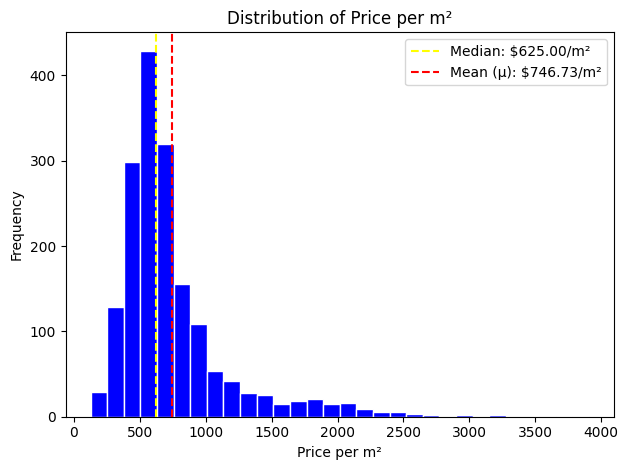

In [4]:
# Step 0) Create Figure and Axis
fig, ax = plt.subplots()

# Step 1) Create the Histogram with 30 bins 
ax.hist(df["price_per_m2"], bins = 30, color = 'blue', edgecolor="white")

# Step 1.2) Create Labels and Titles
ax.set_title("Distribution of Price per m\u00b2")
ax.set_xlabel("Price per m\u00b2")
ax.set_ylabel("Frequency")

# Step 2) Vertical Line for the Median 
median_price_per_m2 = df["price_per_m2"].median()
ax.axvline(median_price_per_m2, color = 'yellow', linestyle = '--', label = f'Median: ${median_price_per_m2:.2f}/m\u00b2')
ax.legend()

# Optional Step 2.2) Vertical Line for the Mean 
mean_price_per_m2 = df["price_per_m2"].mean()
ax.axvline(mean_price_per_m2, color = 'red', linestyle = '--', label = f'Mean (\u00b5): ${mean_price_per_m2:.2f}/m\u00b2')
ax.legend()
plt.tight_layout()

##### **$\underline{\mathbf{Statistical \space Conclusions}}$**
**Right-Skew: (long right** We have extreme values such as the maximum value of USD 3 906.25 while both the mean (USD 746.73) and the median (USD 625) are significantly smaller.   
**Median is the Measure of Central Tendancy:** Extreme values pulling the mean up. Visually Median is to the left of the center of the distribution $\therefore$ an immediate tell of a right skew. 

<div class = "alert alert-block alert-success"><b>Grouped Analysis: The Location Effect</b></div>

Now grouping the observations by state using the metric `price_m2` we get the location effect scaled to states and not just individual observations which will confirm whether or not location matters past our current unravellings. 

How much variation in `price_per_m2` is explained by the state that property is in? ("What's location's influence?")
   
1) Observations are grouped by states
2) There is `price_per_m2` trends that will arise per state now


**The Grouping Analysis**

1) Aggregate = Summary Statistic per group/state (use `.groupby().agg()`)
2) Rank = sort + find extreme values 
3) VIsiualise = boxplot by group/state, to see overall spread
4) Quantify = Summary Statistic that meansures magnitudes of group differences rather than their "distances"



Now we get the state summary statistics, ordered and sorted in the format of the boxplot to be made:

In [5]:
state_price_stats = (
    df.groupby("state")["price_per_m2"]
    .agg(['mean', 'median', 'std']) # because we are creating a boxplot the sum of all these stats will be quiet useful 
    .sort_values(by='median', ascending=False) # best measure of central tendency for this data set 
    .round(2)
)

print(f"\n Price per m\u00b2 Statistics by State: \n")
state_price_stats 


 Price per m² Statistics by State: 



,mean,median,std
state,,,
Distrito Federal,1293.13,1052.96,717.64
Guerrero,802.42,750.20,276.62
Quintana Roo,778.34,721.14,272.99
Estado de México,767.58,717.41,359.86
Querétaro,715.20,664.77,247.54
Baja California Sur,680.04,657.64,219.14
Jalisco,765.95,651.11,403.06
Morelos,649.60,642.14,167.05
Guanajuato,633.57,627.22,92.31


**Ranks states** by **most expensive** to **least expensive** based on the **price per $m^2$** (using **median as the measure of central tendency and basis of the ordinal scale**) 

##### **Top States (Highest Median)**
-  **Distrito Federal** — Mexico's capital city, where urban density makes land  extremely scarce. Every m² of space competes with millions of residents and businesses.
- **Coastal or tourist states** — resort areas where international demand drives up per-m² prices beyond what local incomes would support.

##### **Bottom States (Lowest Median)**
- Rural, agricultural states with low population density, abundant land, and limited economic activity.

##### **Standard Deviation Here**
- Measures how consistently similar the prices per $m^2$ in a singular state.     
  - $\uparrow \sigma$ means a diverse market (mansions, penthouses, apartments, plots, farms, studios, condo's, sub-urban houses....etc) where there may be a number of variables affecting the house prices... $\therefore$ the price per $m^2$
  
   - $\downarrow \sigma$ More constant prices - fairly uniform market.
 

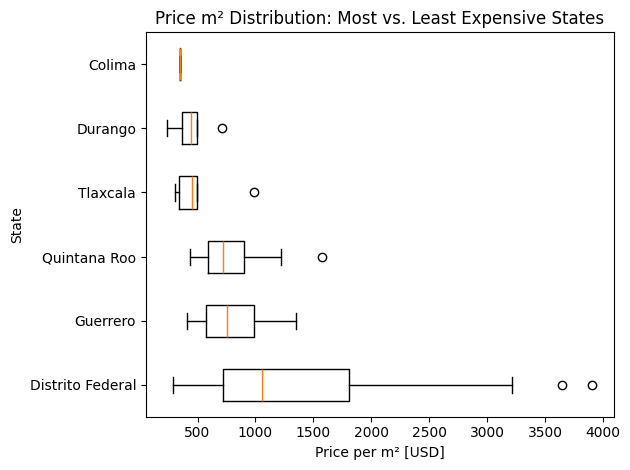

In [6]:
# Step 1) Identify the States we want to plot (top 3 & bottom 3)

top_states = state_price_stats.head(3).index.tolist() #top 3 lines of the the head() method which returns 5 when unspecified
bottom_states = state_price_stats.tail(3).index.tolist() # bottom 3 lines of the DataFrame (full df already organised in decending order)
target_states = top_states + bottom_states 

'''
Right now the state names are sitting in a list with no other data related to the observations recorded in that list of top 3 and bottom 3 
So we need to find all observations per the state and aggregate those observations and their charactersitics (area_m2, price_usd, 
state_price_stat, price_per_m2) and then attatch it for the sake of the plot on the basis of the structure contained in state_price_stats 
for a box and whisker plot to be specific. 
'''
# Step 2) Filter Data by Target States (show observations for only the top/bottom 3 states)

df_states = df[df["state"].isin(target_states)] # we filter by refrencing the column containing state names as a series to match the target states against and then add them to the dataframe df_states

# Step 3) Prep the data for ploting 

date_to_plot = [df_states[df_states["state"] == state]["price_per_m2"] for state in target_states] 

# Step 4) Plot 

fig, ax = plt.subplots()

ax.boxplot(date_to_plot, tick_labels=target_states, vert=False)
ax.set_title("Price m\u00b2 Distribution: Most vs. Least Expensive States")
ax.set_xlabel("Price per m\u00b2 [USD]")
ax.set_ylabel("State")

plt.tight_layout()
plt.show()


There is a massive price discrepancy(variation) between the top 3 states and the bottom 3 states. The median of Distrito Federal is greater than or approaches the maximum of the least expensive states. The mean of the entire data frame, over and above its issue contained in extreme values, ceases to display the within-state variation that exists - the inequality within a state has high variability due to the prices as well as indirect cuaslities like location, population density, lifestyle benefits...etc. 
    

##### **Small Sample Caution**

- The state Colima almost looks invisible because the dataset has very few Colima listings - it's distribution is not a reliable estmate
- Hence its statistical and explanitory power should be used as indicative and not definative
- always double check sample size by using `df.groupby("state").size()` when comparing groups


<div class="alert alert-block alert-success"><b>Variation Decomposition: Quantifying Location vs. Size Effect</b></div>

Boxplots show the location effect visually. Now let's quantify it: what fraction of the total variation in `price_usd` (consequently `price_per_m2`) comes from *between-state* differences vs *within-state* differences?   

**Variance decomposition — the concept**
>
> The total variance in price can be broken into two parts:
>
> - **Between-state variance:** the variance in the *mean* price across states.
>   If all states had the same average price, this would be zero. A high
>   between-state variance means location (which state you are in) explains
>   a lot of the price variation -> i.e. greater spread between inter-state prices = more explanatory power embodied by location
>
> - **Within-state variance:** the average variance *within* each state.
>   Even if you control for which state you are in, prices vary within a state
>   due to city, neighborhood, size, and property type differences.
>
> **Interpretation:** if between-state variance >> within-state variance (variance between state is much larger than that of the variance within state), then knowing which state a property is in explains more of its price than any within-state factor (like size). This directly answers our research question.

Now we quantify the effect through correlation

In [9]:
# Step 1) Correlation between size and price 
size_price_correlation = df[["area_m2", "price_usd"]].corr().iloc[0, 1]
print(f'Correlation between Area and Price: {size_price_correlation:.3f}')

# Step 2) Calculate Variance Components (Total Variance in Price USD)
total_variance = df["price_usd"].var()

# Step 3) Between State Variance (Variance of the State Means, not the Medians)
state_means = df.groupby("state")["price_usd"].mean()
between_state_variance = state_means.var()

# Step 4) Within-State Variance (Average Variance within each State)
within_state_variance = df.groupby("state")["price_usd"].var().mean() #first takes the prices and groups them by state then calculates the variation for each state whereafter the variation is averaged across all states

# Step 5) Calculate Percentages 
between_state_var_pct = (between_state_variance/total_variance) * 100
within_state_var_pct = (within_state_variance/total_variance) * 100 

print(f'\n Variance Decomposition \n')
print(f'Between-State Variance: {between_state_var_pct:.1f}%')
print(f'Within-State Variance: {within_state_var_pct:.1f}%')
print(f'Between-Within State Ratio: {between_state_variance/within_state_variance:.2f}')

Correlation between Area and Price: 0.585

 Variance Decomposition 

Between-State Variance: 12.6%
Within-State Variance: 81.5%
Between-Within State Ratio: 0.16



 **Reading the variance decomposition output**
>
> **If between-state variance > within-state variance:**
> This is the decisive evidence for the "location matters more" hypothesis.
> Knowing which state a property is in reduces our uncertainty about its price
> by more than knowing how large it is. The location effect is quantifiably
> larger than the size effect.
>
> **If within-state variance > between-state variance:**
> The market is more uniform across states, and within-state variation (driven
> by size, property type, neighborhood) dominates.
>
> **The ratio (between/within):**
> A ratio > 1.0 means between-state differences explain more than within-state
> differences — location dominates. A ratio < 1.0 means within-state differences
> dominate — other factors matter more.
>
> > **This variance decomposition is a simplified version of a formal
> > statistical technique called ANOVA (Analysis of Variance)**, which we
> > will encounter in more advanced courses. Here, we are doing the intuitive
> > version: computing group-level and within-group variances directly. The
> > conceptual result is the same: how much does knowing the group (state)
> > reduce our uncertainty about the outcome (price)?

<div class="alert alert-block alert-success"><b>The Property Type Effect</b></div>

Does property type drive price? is it statistically significant on the other hand does it have explanatory power? 

- for example are apartments denser value stores than houses?

Price per m² by Property Type: 

                  mean  median  count
property_type                        
apartment      1158.20  987.87    407
house           620.72  581.83   1329


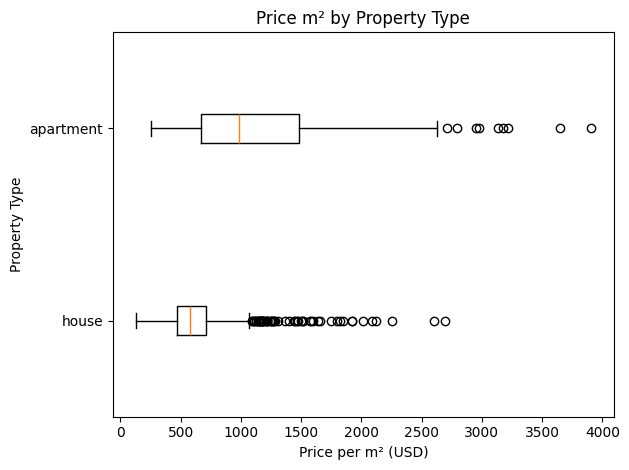

In [15]:
# Step 1) Calculate the Summary Stats by Property_Type
property_type_stats = (
    df
    .groupby("property_type")
    ["price_per_m2"]
    .agg(['mean','median', 'count'])
    .round(2)
)

print("Price per m\u00b2 by Property Type: \n")
print(property_type_stats)

# Step 2) Get unique Property Types (no repetition)
prop_types = df["property_type"].unique()

# Step 3) Prepare Data List 
data_by_type = [df[df["property_type"] == p_type]["price_per_m2"] for p_type in prop_types] # Iterates through each unique property type, filters the
                                                                                            # DataFrame to retain only observations belonging to that
                                                                                            # property type, extracts their corresponding price_per_m2
                                                                                            # values as a Pandas Series, and appends each Series to a list.
# Step 4) Plot the data

fig, ax = plt.subplots()

ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)
ax.set_title("Price m\u00b2 by Property Type") 
ax.set_xlabel("Price per m\u00b2 (USD)")
ax.set_ylabel("Property Type")

plt.tight_layout()
plt.show()

**Apartments (typically higher `price_per_m2`):**
> - Higher median — apartments command significantly more per square meter.
>   This confirms the Law of Diminishing Returns from Lesson 3: smaller
>   properties (apartments) are more expensive per unit of space.
> - Wider box — high within-type variation. The apartment market spans from
>   modest studios in suburban areas to luxury penthouses in central locations.
>   Both are apartments, but their `price_per_m2` differs by 10× or more.
>
**Houses (typically lower `price_per_m2`):**
> - Lower median — houses are cheaper per square meter.
> - Narrow box — the house market is more uniform. Most houses have roughly
>   similar price-per-m² because size is the dominant value driver (as we saw
>   from the higher correlation in Lesson 3).
> - Right-tail outliers — a subset of high-value houses (luxury properties with
>   large footprints in expensive areas) appear as outlier dots.
>
**Why apartments are more expensive per m²:**
>
> Three reinforcing factors:
>
> 1. **Location premium:** apartments are concentrated in urban centers where land
>    is scarce and competition is intense. City-center land is worth more per m².
> 2. **Amenity bundling:** building amenities (pool, gym, security, lobby) impose
>    fixed costs distributed across fewer square meters than in a standalone house.
>    The per-m² cost is therefore higher.
> 3. **Diminishing returns (from Lesson 3):** the first square meter of living
>    space is more valuable than the 200th. Small apartments maximize value per m²
>    simply because they have fewer square meters to dilute the premium.
>
**Connecting to Lesson 3:**
> In Lesson 3, we observed that size explains less of apartment prices (r ≈ 0.52)
> than house prices (r ≈ 0.72). Now we see why: apartments are priced more by
> location and amenities (which correlate weakly with size) than by raw square
> footage.

<div class = "alert alert-block alert-info">
    <b> Combined Analysis: State (Location) and Property Type
</div>

It is a question of co-variance. We now know that both loaction and property type are statistically significant so we must ask how do they interact? 

In [22]:
# Step 1) Group by state and property type 

combined_stats = (
    df.groupby(["state", "property_type"])
    ["price_per_m2"]
    .agg(['mean', 'median', 'count'])
    .round(2)
)

# Step 2) Filter for groups with at least 5 properties

combined_stats_filtered = combined_stats[combined_stats['count'] >= 5] # for each state with property type x, we want that group with more than 5 or exactly 5 observations

# Step 3) Sort filtered DataFrame by median price per m²
combined_stats_filtered = combined_stats_filtered.sort_values(by='median', ascending=False)

print("\n Top 15 State-Property Type Combinations: \n")
display(combined_stats_filtered.head(15))

print("\n Bottom 10 State-Property Type Combinations: \n")
combined_stats_filtered.tail(10)


 Top 15 State-Property Type Combinations: 



,,mean,median,count
state,property_type,,,
Distrito Federal,apartment,1460.80,1344.79,140
Jalisco,apartment,1471.45,1276.04,7
Querétaro,apartment,1251.58,1197.42,7
Quintana Roo,apartment,1076.74,1107.26,6
Puebla,apartment,1028.06,1018.52,15
Nuevo León,apartment,1279.17,1003.09,7
Yucatán,apartment,889.87,919.40,15
Estado de México,apartment,1126.61,900.41,14
Guerrero,apartment,838.45,790.42,22



 Bottom 10 State-Property Type Combinations: 



,,mean,median,count
state,property_type,,,
Tabasco,house,537.64,564.50,13
Hidalgo,house,526.63,563.34,12
Nuevo León,house,543.63,522.22,46
Sonora,house,471.44,507.69,9
Yucatán,house,520.97,500.00,115
San Luis Potosí,house,501.81,488.12,34
Sinaloa,house,477.66,486.91,16
Veracruz de Ignacio de la Llave,house,500.95,465.13,72
Aguascalientes,house,465.36,455.86,8
